# 03. Проверка токенов и границы валидации

До 12 сообщений каждой группы аэропорт × год плюс редкие облачные форматы,
остаточные сообщения и числовые аномалии. Детерминированная выборка;
обогащение редкими случаями не допускает чтения частоты замечаний как оценки
частоты ошибок в полном архиве.

Отдельный лексический алгоритм читает простые числовые токены, без импорта
рабочего декодера. Сравнение проверяет преобразование кодов, а не реальную
погоду. IEM также использует python-metar: согласие с рабочим строгим парсером
не было бы полностью независимой проверкой.


In [1]:
from pathlib import Path
import hashlib,json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
BASE=Path.cwd().resolve().parent
PROJECT=BASE.parents[1]
R,F=BASE/'reports',BASE/'figures'
GREEN,RED='#00897B','#D65A4A'
plt.rcParams.update({'figure.dpi':120,'font.size':11,'axes.grid':True,'grid.alpha':.15,'axes.spines.top':False,'axes.spines.right':False})
def sha(path):
    with path.open('rb') as stream:return hashlib.file_digest(stream,'sha256').hexdigest()
def save(name):
    plt.tight_layout()
    for ext in ['png','svg']:plt.savefig(F/f'{name}.{ext}',bbox_inches='tight')
    plt.show()
    plt.close()
manifest=json.loads((R/'02_study_manifest.json').read_text(encoding='utf8'))
assert sha(PROJECT/'europe/data/analytical/06_05_cases_excluded.parquet')==manifest['input_sha256']
assert sha(BASE/'protocol.md')==manifest['protocol_sha256']
assert manifest['primary_reproduced'] and manifest['all_rows_once'] and not manifest['training_executed']
summary=pd.read_csv(R/'02_scenario_summary.csv')
strata=pd.read_csv(R/'02_scenario_strata.csv')
pd.set_option('display.max_columns',20)
pd.set_option('display.max_rows',50)


,sample_messages,lexical_comparisons,lexical_disagreements,semantic_fixture_cases,semantic_fixture_comparisons,semantic_fixtures_pass,physical_weather_independently_verified,independent_human_annotation,training_executed,seed,bootstrap_replicates,disagreement_messages,all_disagreement_cores_blocked
0,19636,133547,8,8,21,True,False,False,False,20261011,2000,4,True


,station,sample_regular,sample_enriched
0,EDDB,60,762
1,EDDF,60,609
2,EDDM,60,1246
3,EGCC,36,4165
4,EGLL,60,4832
5,EGSS,60,4376
6,EHAM,60,23
7,EIDW,60,171
8,EKCH,60,103
9,EPWA,60,1


agrees,False,True
field,,
dewpoint_c,0,19614
qnh_hpa,0,19602
temperature_c,0,19614
visibility_m,4,18461
visibility_relation,4,18461
wind_direction_deg,0,18183
wind_speed_kt,0,19604


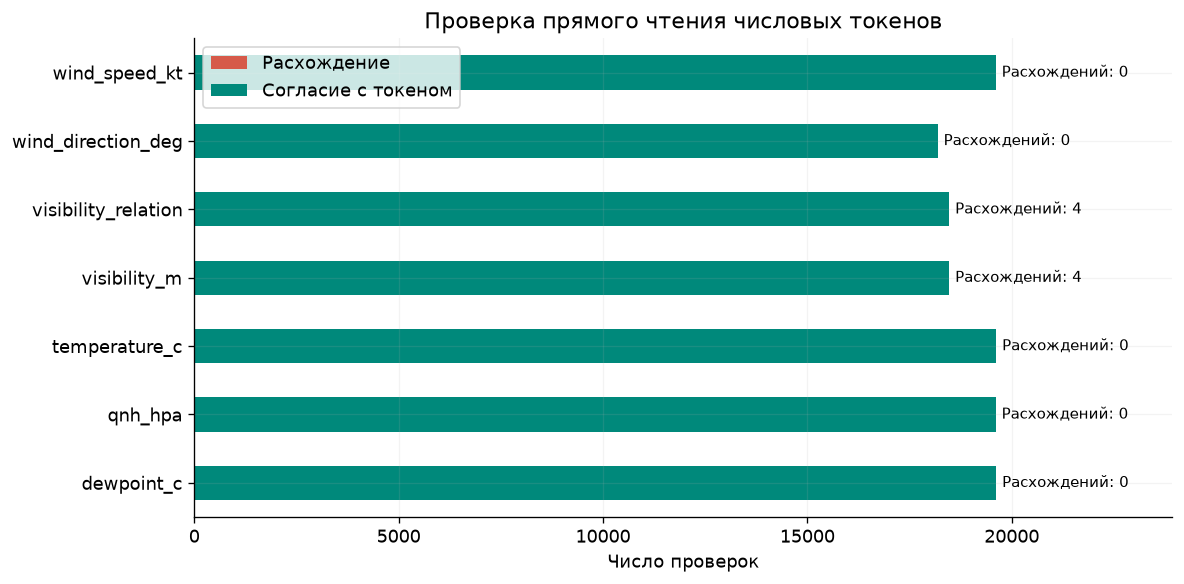

,metar_id,station,field,token,expected,actual,agrees,sample_regular,sample_enriched
10134,a05bc0ec65f4351d2296a5ebfefa8898bfdede4d2df2a6...,EDDM,visibility_m,9999,10000,NaN,False,False,True
10135,a05bc0ec65f4351d2296a5ebfefa8898bfdede4d2df2a6...,EDDM,visibility_relation,9999,ge,missing,False,False,True
10141,b634007cff7a0b54dca6b9d77386071d910921981c7875...,EDDM,visibility_m,9999,10000,NaN,False,False,True
10142,b634007cff7a0b54dca6b9d77386071d910921981c7875...,EDDM,visibility_relation,9999,ge,missing,False,False,True
67575,07acb73243cb9eec66d5423edd9fbf3f8085dd7c23d81f...,EGLL,visibility_m,9999,10000,NaN,False,False,True
67576,07acb73243cb9eec66d5423edd9fbf3f8085dd7c23d81f...,EGLL,visibility_relation,9999,ge,missing,False,False,True
116548,57588237618b3feb6761d0345f983f3940c2635f5e5186...,LEMD,visibility_m,9999,10000,NaN,False,False,True
116549,57588237618b3feb6761d0345f983f3940c2635f5e5186...,LEMD,visibility_relation,9999,ge,missing,False,False,True


,metar_id,station,metar_utc,metar,decode_issues,decoded_candidate,core_validated,visibility_token,adjudication
0,a05bc0ec65f4351d2296a5ebfefa8898bfdede4d2df2a6...,EDDM,2020-05-16 09:50:00+00:00,EDDM 160950Z 04005KT 010/V090 9999 FEW036 13/0...,parser_error;visibility_format_outside_pilot_s...,False,False,010/V090,readable_9999_after_unsupported_structure; con...
1,b634007cff7a0b54dca6b9d77386071d910921981c7875...,EDDM,2020-05-16 10:20:00+00:00,EDDM 161020Z 07006KT 030/V120 9999 FEW036 14/0...,parser_error;visibility_format_outside_pilot_s...,False,False,030/V120,readable_9999_after_unsupported_structure; con...
2,07acb73243cb9eec66d5423edd9fbf3f8085dd7c23d81f...,EGLL,2021-07-19 08:50:00+00:00,COR EGLL 190850Z AUTO 22004KT 180V2NOSIG50 999...,parser_error;visibility_format_outside_pilot_s...,False,False,180V2NOSIG50,readable_9999_after_unsupported_structure; con...
3,57588237618b3feb6761d0345f983f3940c2635f5e5186...,LEMD,2019-04-09 15:00:00+00:00,LEMD 091500Z 29017KT 250V330 VCTS 9999 FEW040C...,parser_error;visibility_format_outside_pilot_s...,False,False,VCTS,readable_9999_after_unsupported_structure; con...


,case,metar,field,expected,actual,agrees
0,partial_cb,LFPG 191155Z 24010KT 9999 ///CB 10/08 Q1002,cumulonimbus_reported,True,True,True
1,partial_cb,LFPG 191155Z 24010KT 9999 ///CB 10/08 Q1002,cloud_amount_unavailable,True,True,True
2,partial_cb,LFPG 191155Z 24010KT 9999 ///CB 10/08 Q1002,cloud_ceiling_ft,NaN,NaN,True
3,partial_tcu,LFPG 191155Z 24010KT 9999 ///TCU 10/08 Q1002,towering_cumulus_reported,True,True,True
4,partial_tcu,LFPG 191155Z 24010KT 9999 ///TCU 10/08 Q1002,cloud_amount_unavailable,True,True,True
5,partial_tcu,LFPG 191155Z 24010KT 9999 ///TCU 10/08 Q1002,cloud_ceiling_ft,NaN,NaN,True
6,all_cloud_unknown,LFPG 191155Z 24010KT 9999 ///////// 10/08 Q1002,cloud_amount_unavailable,True,True,True
7,all_cloud_unknown,LFPG 191155Z 24010KT 9999 ///////// 10/08 Q1002,cloud_type_unavailable,True,True,True
8,all_cloud_unknown,LFPG 191155Z 24010KT 9999 ///////// 10/08 Q1002,cloud_ceiling_ft,NaN,NaN,True
9,all_cloud_unknown,LFPG 191155Z 24010KT 9999 ///////// 10/08 Q1002,cavok,False,False,True


In [2]:
validation=json.loads((R/'05_validation_manifest.json').read_text(encoding='utf8'))
display(pd.DataFrame([validation]))
registry=pd.read_csv(R/'05_audit_sample_registry.csv')
display(registry.groupby('station')[['sample_regular','sample_enriched']].sum().reset_index())
audit=pd.read_csv(R/'05_lexical_validation.csv')
counts=audit.groupby(['field','agrees']).size().unstack(fill_value=0)
display(counts)
fig,ax=plt.subplots(figsize=(10,5))
counts.rename(columns={True:'Согласие с токеном',False:'Расхождение'}).plot.barh(stacked=True,ax=ax,color=[RED,GREEN] if False in counts.columns else [GREEN])
ax.set(xlabel='Число проверок',ylabel='',title='Проверка прямого чтения числовых токенов')
for position,field in enumerate(counts.index):
    errors=int(counts.loc[field,False]) if False in counts else 0
    ax.text(counts.loc[field].sum()+150,position,f'Расхождений: {errors}',va='center',fontsize=9)
ax.set_xlim(0,float(counts.sum(axis=1).max())*1.22)
ax.legend()
save('07_lexical_validation')
display(audit.loc[~audit.agrees].head(50))
adjudication=pd.read_csv(R/'05_disagreement_adjudication.csv')
assert (~adjudication.decoded_candidate & ~adjudication.core_validated).all()
display(adjudication)
fixtures=pd.read_csv(R/'05_semantic_fixtures.csv')
assert fixtures.agrees.all()
display(fixtures)


Ожидания для восьми примеров заданы явно по руководствам и
консервативной политике неизвестных облачных компонент. Это авторские
ожидания, не разметка независимого метеоролога. Девять слешей проверяют
политику проекта, а не нормативность группы. Вертикальная видимость
сохраняется отдельно от нижней границы облаков.

Восемь расхождений относятся к четырем сообщениям с неподдержанной
структурой перед читаемым 9999. Все четыре основные части заблокированы;
исходные тексты не исправляются. Полный разбор приведен в таблице выше.

Не установлены: фактическая физическая правильность всех наблюдений,
время исторического получения и происхождение каждой числовой аномалии.
Полная внешняя ручная валидация остается ограничением публикации.
Источники и разграничение вклада: literature/01_positioning_and_sources.md.
